In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi']=100

In [6]:
df = pd.read_csv('../data/raw/flight_data.csv')
print('Rows, Columns:', df.shape)

Rows, Columns: (255, 11)


In [7]:
df.head()


,Booking_ID,Booking_Date,Source_City,Travel_Class,Booking_Channel,Airline_Type,Distance_Km,Days_Before_Departure,Passenger_Age,Baggage_Kg,Ticket_Price_INR
0,B1014,2026-01-01,Mumbai,Economy,Mobile_App,Low_Cost,655,26.0,NaN,14.0,2320
1,B1031,2025-06-19,Delhi,Economy,Mobile_App,Low_Cost,1420,79.0,38.0,19.0,1800
2,B1100,2026-09-14,Delhi,Premium_Economy,Website,Low_Cost,1347,41.0,34.0,22.0,2530
3,B1192,2024-12-28,Delhi,Economy,Website,Full_Service,589,15.0,38.0,18.0,2520
4,B1120,2025-11-05,Kolkata,Economy,Website,Full_Service,1844,35.0,24.0,7.0,5050


In [8]:
df.tail()

,Booking_ID,Booking_Date,Source_City,Travel_Class,Booking_Channel,Airline_Type,Distance_Km,Days_Before_Departure,Passenger_Age,Baggage_Kg,Ticket_Price_INR
250,B1040,2025-10-15,Delhi,Economy,Website,Low_Cost,836,34.0,50.0,8.0,3100
251,B1138,2025-08-26,Kolkata,Economy,Website,Low_Cost,867,15.0,43.0,10.0,2360
252,B1107,2025-06-04,Kolkata,Economy,Mobile_App,Full_Service,1611,30.0,55.0,20.0,3750
253,B1246,2024-12-04,Chennai,Economy,Travel_Agent,Full_Service,606,28.0,23.0,14.0,1800
254,B1024,2025-10-25,Delhi,Economy,Mobile_App,Full_Service,1682,58.0,38.0,17.0,2890


In [9]:
print("dataset shape", df.shape)
print("no. of row",df.shape[0])
print("no. of column", df.shape[1])

dataset shape (255, 11)
no. of row 255
no. of column 11


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Booking_ID             255 non-null    str    
 1   Booking_Date           255 non-null    str    
 2   Source_City            255 non-null    str    
 3   Travel_Class           255 non-null    str    
 4   Booking_Channel        251 non-null    str    
 5   Airline_Type           255 non-null    str    
 6   Distance_Km            255 non-null    int64  
 7   Days_Before_Departure  250 non-null    float64
 8   Passenger_Age          250 non-null    float64
 9   Baggage_Kg             249 non-null    float64
 10  Ticket_Price_INR       255 non-null    int64  
dtypes: float64(3), int64(2), str(6)
memory usage: 22.0 KB


In [11]:
print('Missing values per column:'); print(df.isna().sum()[df.isna().sum()>0])


Missing values per column:
Booking_Channel          4
Days_Before_Departure    5
Passenger_Age            5
Baggage_Kg               6
dtype: int64


In [12]:
print('\nDuplicate rows:', df.duplicated().sum())
df.describe().round(1)



Duplicate rows: 5


,Distance_Km,Days_Before_Departure,Passenger_Age,Baggage_Kg,Ticket_Price_INR
count,255.0,250.0,250.0,249.0,255.0
mean,1284.3,32.0,37.8,15.0,4105.6
std,530.4,19.9,16.4,5.9,1894.6
min,300.0,2.0,-27.0,0.0,1800.0
25%,892.5,17.0,29.0,11.0,2490.0
50%,1260.0,28.0,36.5,16.0,3870.0
75%,1688.5,43.0,44.8,19.0,5295.0
max,2713.0,90.0,214.0,30.0,10200.0


In [13]:
clean = df.copy()

In [14]:
clean = clean.drop_duplicates()
print(clean.shape)


(250, 11)


In [15]:

print(clean.isnull().sum())


Booking_ID               0
Booking_Date             0
Source_City              0
Travel_Class             0
Booking_Channel          4
Airline_Type             0
Distance_Km              0
Days_Before_Departure    5
Passenger_Age            5
Baggage_Kg               6
Ticket_Price_INR         0
dtype: int64


In [16]:
clean['Booking_Channel'] = clean['Booking_Channel'].fillna(clean['Booking_Channel'].mode()[0])

In [17]:
print(clean['Booking_Channel'].isnull().sum())

0


In [18]:
print(clean['Days_Before_Departure'].median())
clean['Days_Before_Departure'] = clean['Days_Before_Departure'].fillna(clean['Days_Before_Departure'].median())
print(clean['Days_Before_Departure'].isnull().sum())

28.0
0


In [19]:
print(clean['Passenger_Age'].median())
clean['Passenger_Age'] = clean['Passenger_Age'].fillna(clean['Passenger_Age'].median())
print(clean['Passenger_Age'].isnull().sum())

37.0
0


In [20]:
print(clean['Baggage_Kg'].median())
clean['Baggage_Kg'] = clean['Baggage_Kg'].fillna(clean['Baggage_Kg'].median())
print(clean['Baggage_Kg'].isnull().sum())

16.0
0


In [21]:
print(clean.isnull().sum())

Booking_ID               0
Booking_Date             0
Source_City              0
Travel_Class             0
Booking_Channel          0
Airline_Type             0
Distance_Km              0
Days_Before_Departure    0
Passenger_Age            0
Baggage_Kg               0
Ticket_Price_INR         0
dtype: int64


In [23]:

print(clean[clean['Passenger_Age'] < 0])
print(clean[clean['Passenger_Age'] > 100])
print("Negative ages:", (clean['Passenger_Age'] < 0).sum())

print("Ages above 100:", (clean['Passenger_Age'] > 100).sum())



   Booking_ID Booking_Date Source_City Travel_Class Booking_Channel  \
55      B1214   2026-07-13      Mumbai      Economy         Website   

    Airline_Type  Distance_Km  Days_Before_Departure  Passenger_Age  \
55  Full_Service          392                   16.0          -27.0   

    Baggage_Kg  Ticket_Price_INR  
55        22.0              3130  
    Booking_ID Booking_Date Source_City     Travel_Class Booking_Channel  \
165      B1185   2025-03-15   Bengaluru  Premium_Economy    Travel_Agent   

    Airline_Type  Distance_Km  Days_Before_Departure  Passenger_Age  \
165     Low_Cost          872                    2.0          214.0   

     Baggage_Kg  Ticket_Price_INR  
165         2.0              4960  
Negative ages: 1
Ages above 100: 1


In [24]:


median_age = clean['Passenger_Age'].median()

clean.loc[
    (clean['Passenger_Age'] < 0) | (clean['Passenger_Age'] > 100),
    'Passenger_Age'
] = median_age


In [25]:

print(clean[(clean['Passenger_Age'] < 0) | (clean['Passenger_Age'] > 100)])

Empty DataFrame
Columns: [Booking_ID, Booking_Date, Source_City, Travel_Class, Booking_Channel, Airline_Type, Distance_Km, Days_Before_Departure, Passenger_Age, Baggage_Kg, Ticket_Price_INR]
Index: []


In [26]:

print(clean.describe())


       Distance_Km  Days_Before_Departure  Passenger_Age  Baggage_Kg  \
count   250.000000             250.000000     250.000000  250.000000   
mean   1289.472000              31.956000      37.436000   14.936000   
std     533.816396              19.728734      11.255606    5.823707   
min     300.000000               2.000000      12.000000    0.000000   
25%     887.750000              17.000000      29.000000   11.000000   
50%    1277.000000              28.000000      37.000000   16.000000   
75%    1697.500000              42.750000      44.000000   19.000000   
max    2713.000000              90.000000      70.000000   30.000000   

       Ticket_Price_INR  
count        250.000000  
mean        4093.200000  
std         1895.630189  
min         1800.000000  
25%         2485.000000  
50%         3865.000000  
75%         5265.000000  
max        10200.000000  


In [27]:

print("Invalid Distance:")
print(clean[clean['Distance_Km'] <= 0])

print("Invalid Days Before Departure:")
print(clean[clean['Days_Before_Departure'] < 0])

print("Invalid Passenger Age:")
print(clean[(clean['Passenger_Age'] < 0) | (clean['Passenger_Age'] > 100)])

print("Invalid Baggage:")
print(clean[clean['Baggage_Kg'] < 0])

print("Invalid Ticket Price:")
print(clean[clean['Ticket_Price_INR'] <= 0])


Invalid Distance:
Empty DataFrame
Columns: [Booking_ID, Booking_Date, Source_City, Travel_Class, Booking_Channel, Airline_Type, Distance_Km, Days_Before_Departure, Passenger_Age, Baggage_Kg, Ticket_Price_INR]
Index: []
Invalid Days Before Departure:
Empty DataFrame
Columns: [Booking_ID, Booking_Date, Source_City, Travel_Class, Booking_Channel, Airline_Type, Distance_Km, Days_Before_Departure, Passenger_Age, Baggage_Kg, Ticket_Price_INR]
Index: []
Invalid Passenger Age:
Empty DataFrame
Columns: [Booking_ID, Booking_Date, Source_City, Travel_Class, Booking_Channel, Airline_Type, Distance_Km, Days_Before_Departure, Passenger_Age, Baggage_Kg, Ticket_Price_INR]
Index: []
Invalid Baggage:
Empty DataFrame
Columns: [Booking_ID, Booking_Date, Source_City, Travel_Class, Booking_Channel, Airline_Type, Distance_Km, Days_Before_Departure, Passenger_Age, Baggage_Kg, Ticket_Price_INR]
Index: []
Invalid Ticket Price:
Empty DataFrame
Columns: [Booking_ID, Booking_Date, Source_City, Travel_Class, Bookin

In [28]:
# Check missing value
print("Missing Values:")
print(clean.isnull().sum())

# Check duplicate rows
print("Duplicate Rows:", clean.duplicated().sum())

# Check final dataset size
print("Final Shape:", clean.shape)

Missing Values:
Booking_ID               0
Booking_Date             0
Source_City              0
Travel_Class             0
Booking_Channel          0
Airline_Type             0
Distance_Km              0
Days_Before_Departure    0
Passenger_Age            0
Baggage_Kg               0
Ticket_Price_INR         0
dtype: int64
Duplicate Rows: 0
Final Shape: (250, 11)


In [29]:
# Overall ticket price analysis

print("Average Price:", clean['Ticket_Price_INR'].mean())

print("Median Price:", clean['Ticket_Price_INR'].median())

print("Minimum Price:", clean['Ticket_Price_INR'].min())

print("Maximum Price:", clean['Ticket_Price_INR'].max())

print("Standard Deviation:", clean['Ticket_Price_INR'].std())



Average Price: 4093.2
Median Price: 3865.0
Minimum Price: 1800
Maximum Price: 10200
Standard Deviation: 1895.6301894781705


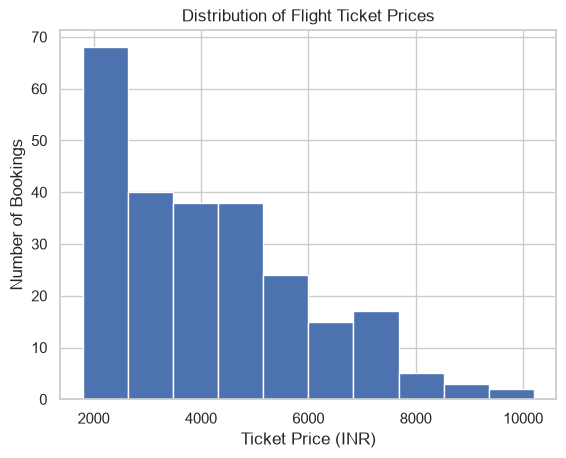

In [30]:

import matplotlib.pyplot as plt

plt.hist(clean['Ticket_Price_INR'], bins=10)

plt.title("Distribution of Flight Ticket Prices")
plt.xlabel("Ticket Price (INR)")
plt.ylabel("Number of Bookings")

plt.show()



Average Price: 4093.2
Median Price: 3865.0
Minimum Price: 1800
Maximum Price: 10200
Standard Deviation: 1895.6301894781705
Skewness: 0.6555320827873293


In [33]:
print(clean[['Distance_Km', 'Days_Before_Departure', 'Ticket_Price_INR']].corr())


                       Distance_Km  Days_Before_Departure  Ticket_Price_INR
Distance_Km               1.000000               0.016163          0.567505
Days_Before_Departure     0.016163               1.000000         -0.432487
Ticket_Price_INR          0.567505              -0.432487          1.000000


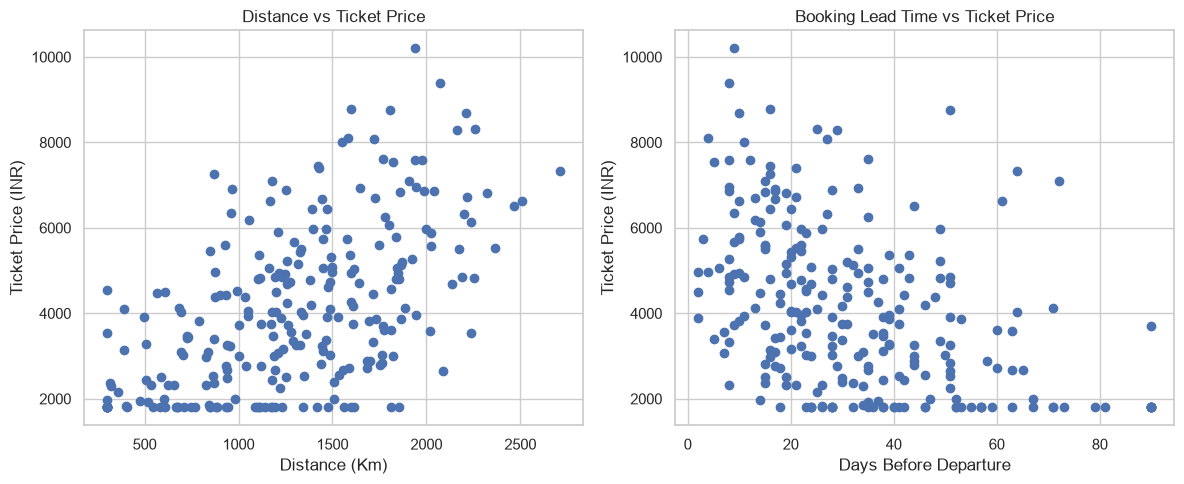

In [34]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(clean['Distance_Km'], clean['Ticket_Price_INR'])
axes[0].set_title("Distance vs Ticket Price")
axes[0].set_xlabel("Distance (Km)")
axes[0].set_ylabel("Ticket Price (INR)")

axes[1].scatter(clean['Days_Before_Departure'], clean['Ticket_Price_INR'])
axes[1].set_title("Booking Lead Time vs Ticket Price")
axes[1].set_xlabel("Days Before Departure")
axes[1].set_ylabel("Ticket Price (INR)")

plt.tight_layout()
plt.show()

In [35]:
print("Average Price by Source City:")
print(clean.groupby('Source_City')['Ticket_Price_INR'].mean().sort_values(ascending=False))

print("\nAverage Price by Travel Class:")
print(clean.groupby('Travel_Class')['Ticket_Price_INR'].mean().sort_values(ascending=False))

print("\nAverage Price by Booking Channel:")
print(clean.groupby('Booking_Channel')['Ticket_Price_INR'].mean().sort_values(ascending=False))

print("\nAverage Price by Airline Type:")
print(clean.groupby('Airline_Type')['Ticket_Price_INR'].mean().sort_values(ascending=False))

Average Price by Source City:
Source_City
kolkata      5680.000000
 Mumbai      5530.000000
Chennai      4391.666667
Mumbai       4214.428571
Delhi        4082.394366
Bengaluru    4060.869565
mumbai       3910.000000
Kolkata      3693.461538
 MUMBAI      2320.000000
Delhi        2290.000000
MUMBAI       2065.000000
Name: Ticket_Price_INR, dtype: float64

Average Price by Travel Class:
Travel_Class
Business           4881.111111
Premium_Economy    4362.203390
Economy            3919.479769
Name: Ticket_Price_INR, dtype: float64

Average Price by Booking Channel:
Booking_Channel
Travel_Agent    4328.679245
Website         4078.170732
Mobile_App      3995.391304
Name: Ticket_Price_INR, dtype: float64

Average Price by Airline Type:
Airline_Type
Full_Service    4395.760870
Low_Cost        3917.025316
Name: Ticket_Price_INR, dtype: float64


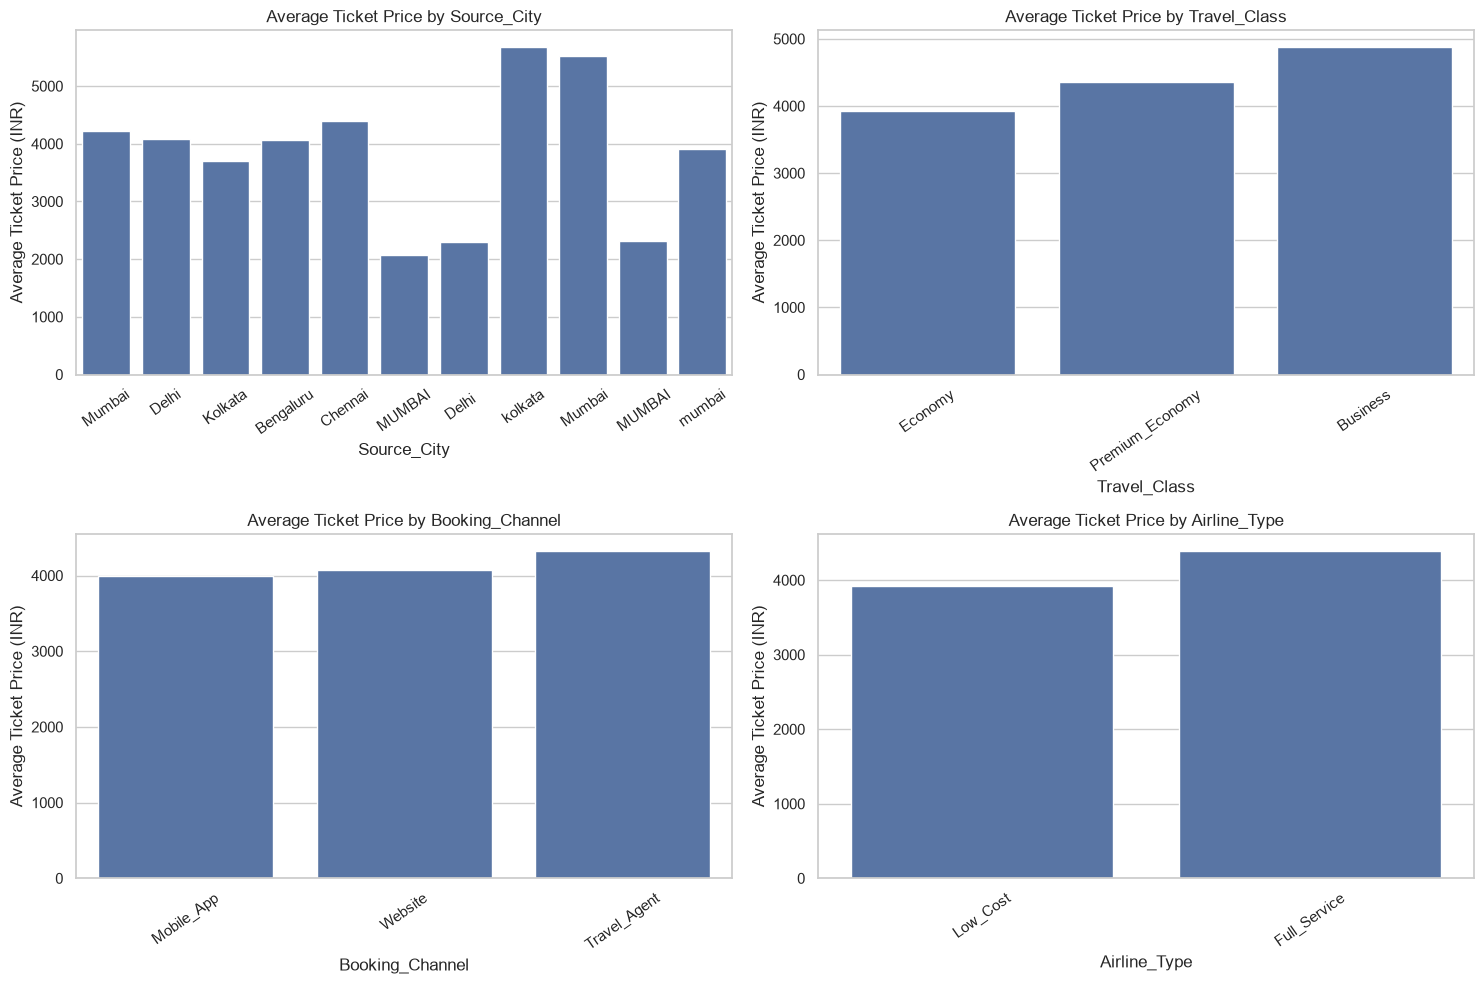

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

columns = ['Source_City', 'Travel_Class', 'Booking_Channel', 'Airline_Type']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for col, ax in zip(columns, axes.flatten()):
    sns.barplot(
        data=clean,
        x=col,
        y='Ticket_Price_INR',
        estimator='mean',
        errorbar=None,
        ax=ax
    )

    ax.set_title(f'Average Ticket Price by {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Average Ticket Price (INR)')
    ax.tick_params(axis='x', rotation=35)

plt.tight_layout()
plt.show()

In [38]:
def categorize_price(price):
    if price > 6000:
        return 'High-Value'
    elif price < 2500:
        return 'Budget'
    else:
        return 'Regular'

clean['Price_Category'] = clean['Ticket_Price_INR'].apply(categorize_price)
print(clean['Price_Category'].value_counts())

Price_Category
Regular       145
Budget         63
High-Value     42
Name: count, dtype: int64


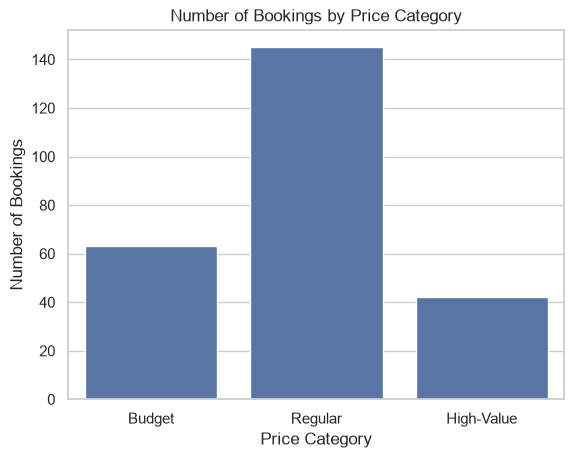

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=clean, x='Price_Category')

plt.title('Number of Bookings by Price Category')
plt.xlabel('Price Category')
plt.ylabel('Number of Bookings')
plt.show()

In [40]:
high_value = clean[clean['Price_Category'] == 'High-Value']
budget = clean[clean['Price_Category'] == 'Budget']

print("HIGH-VALUE BOOKINGS")
print(high_value[['Distance_Km', 'Days_Before_Departure', 'Travel_Class', 'Airline_Type']].mean(numeric_only=True))
print(high_value['Travel_Class'].value_counts())
print(high_value['Airline_Type'].value_counts())

print("\nBUDGET BOOKINGS")
print(budget[['Distance_Km', 'Days_Before_Departure', 'Travel_Class', 'Airline_Type']].mean(numeric_only=True))
print(budget['Travel_Class'].value_counts())
print(budget['Airline_Type'].value_counts())

HIGH-VALUE BOOKINGS
Distance_Km              1770.642857
Days_Before_Departure      21.857143
dtype: float64
Travel_Class
Economy            21
Premium_Economy    14
Business            7
Name: count, dtype: int64
Airline_Type
Full_Service    21
Low_Cost        21
Name: count, dtype: int64

BUDGET BOOKINGS
Distance_Km              839.301587
Days_Before_Departure     45.317460
dtype: float64
Travel_Class
Economy            44
Premium_Economy    15
Business            4
Name: count, dtype: int64
Airline_Type
Low_Cost        45
Full_Service    18
Name: count, dtype: int64


In [41]:
clean.to_csv("flight_analysis_final.csv", index=False)
print("Final cleaned dataset saved successfully!")

Final cleaned dataset saved successfully!
